In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
url = "https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv"
data = pd.read_csv(url)
data.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [4]:
numerical = data.select_dtypes(include=['number']).columns.to_list()
categorical = data.select_dtypes(include=['object','category']).columns.to_list()

In [5]:
data[categorical] = data[categorical].fillna('NA')
data[numerical] = data[numerical].fillna(0)

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,roc_auc_score
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import KFold,cross_val_score


In [7]:
df_full_train, df_test = train_test_split(data, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

In [8]:
y_train = df_train['converted'].values
y_val = df_val['converted'].values
y_test = df_val['converted'].values

df_train = df_train.drop(columns = ['converted'])
df_val = df_val.drop(columns = ['converted'])
df_test = df_test.drop(columns = ['converted'])

In [9]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

In [10]:
transformer = ColumnTransformer(transformers=
                                [('categorical',OneHotEncoder(),categorical)],
                                remainder='passthrough')
pipe = Pipeline(steps=[('transformer',transformer),
                       ('model',LogisticRegression(random_state=42))])

In [11]:
pipe.fit(df_train,y_train)

c:\Users\user\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('transformer', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['lead_source','industry','employment_status',..., 'number_of_courses_viewed','interaction_count','lead_score']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``

In [12]:
y_preds = pipe.predict(df_val)
accuracy = accuracy_score(y_val,y_preds)
accuracy

0.722

Question 1: ROC AUC feature importance

In [13]:
from sklearn.metrics import roc_curve
fpr, tpr, thresholds = roc_curve(y_val, y_preds)

In [14]:
numerical_cols = ['annual_income', 'number_of_courses_viewed', 'interaction_count',
       'lead_score']
auc_res = {}
for col in numerical_cols:
    values = df_train[col]

    auc = roc_auc_score(y_train,values)

    if auc < 0.5:
        auc = roc_auc_score(y_train,-values)
    auc_res[col] = auc

auc_series = pd.Series(auc_res).sort_values(ascending=False)
auc_series

lead_score                  0.788225
interaction_count           0.764920
number_of_courses_viewed    0.722989
annual_income               0.608198
dtype: float64

In [15]:
from sklearn.feature_extraction import DictVectorizer

dv = DictVectorizer(sparse=False)
features = numerical_cols + categorical
train_dict = df_train[features].to_dict(orient="records")
X_train = dv.fit_transform(train_dict)
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train,y_train)

,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalt

In [16]:
val_dict = df_val[features].to_dict(orient='records')
X_val = dv.transform(val_dict)
y_pred = model.predict(X_val)

auc = roc_auc_score(y_val,y_pred)
print(f'AUC : {auc:.3f}')

AUC : 0.598


In [17]:
categorical

['lead_source', 'industry', 'employment_status', 'location']

Question 3: Precision and Recall

Now let's compute precision and recall for our model.

* Evaluate the model on all thresholds from 0.0 to 1.0 with step 0.01
* For each threshold, compute precision and recall
* Plot them

At which threshold precision and recall curves intersect? Ignore thresholds at which both metrics are zero, and choose the threshold with the smallest absolute difference between precision and recall.

In [18]:
def tpr_fpr_df(y_val,y_pred):
    scores = []
    thresholds = np.linspace(0,1,101)
    for t in thresholds:
        actual_pos = (y_val == 1)
        actual_neg = (y_val == 0)

        pred_pos = (y_pred >= t)
        pred_neg = (y_pred < t)

        tp = (pred_pos & actual_pos).sum()
        tn = (pred_neg & actual_neg).sum()

        fp = (pred_pos & actual_neg).sum()
        fn = (pred_neg & actual_pos).sum()

        scores.append((t,tp,fp,fn,tn))

    columns = ['threshold', 'tp', 'fp', 'fn', 'tn']
    df_scores = pd.DataFrame(scores,columns=columns)

    df_scores['tpr'] = df_scores.tp / (df_scores.tp + df_scores.fn)
    df_scores['fpr'] = df_scores.fp / (df_scores.fp + df_scores.tn)

    df_scores['precision'] = df_scores.tp / (df_scores.tp + df_scores.fp)
    df_scores['recall'] = df_scores.tp / (df_scores.tp + df_scores.fn)

    valid_scores = df_scores[(df_scores['precision']!=0) | (df_scores['recall']!=0)]
    valid_scores['abs_diff'] = abs(valid_scores['precision'] - valid_scores['recall'])

    intersection = valid_scores.sort_values(by='abs_diff').head(1)
    print(intersection[['threshold', 'precision', 'recall', 'abs_diff']])
    return df_scores

y_pred_proba = model.predict_proba(X_val)[:,1]
df_scores = tpr_fpr_df(y_val,y_pred_proba)


    threshold  precision    recall  abs_diff
63       0.63   0.732759  0.725256  0.007503


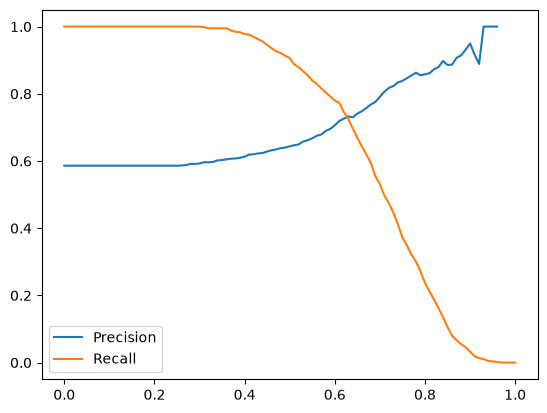

In [19]:
plt.plot(df_scores.threshold, df_scores['precision'], label='Precision')
plt.plot(df_scores.threshold, df_scores['recall'], label='Recall')
plt.legend();

Question 4: F1 score

Precision and recall are conflicting - when one grows, the other goes down. That's why they are often combined into the F1 score - a metrics that takes into account both

This is the formula for computing F1:

F1 = 2⋅P⋅R / (P + R)
Where P is precision and R is recall.

Let's compute F1 for all thresholds from 0.0 to 1.0 with increment 0.01

At which threshold F1 is maximal?

In [20]:
def tpr_fpr_df(y_val,y_pred):
    scores = []
    thresholds = np.linspace(0,1,101)
    for t in thresholds:
        actual_pos = (y_val == 1)
        actual_neg = (y_val == 0)

        pred_pos = (y_pred >= t)
        pred_neg = (y_pred < t)

        tp = (pred_pos & actual_pos).sum()
        tn = (pred_neg & actual_neg).sum()

        fp = (pred_pos & actual_neg).sum()
        fn = (pred_neg & actual_pos).sum()

        scores.append((t,tp,fp,fn,tn))

    columns = ['threshold', 'tp', 'fp', 'fn', 'tn']
    df_scores = pd.DataFrame(scores,columns=columns)

    df_scores['tpr'] = df_scores.tp / (df_scores.tp + df_scores.fn)
    df_scores['fpr'] = df_scores.fp / (df_scores.fp + df_scores.tn)

    df_scores['precision'] = df_scores.tp / (df_scores.tp + df_scores.fp)
    df_scores['recall'] = df_scores.tp / (df_scores.tp + df_scores.fn)
    df_scores['f1'] = np.where((df_scores['precision']+df_scores['recall'])==0,0,
        2 * ((df_scores['precision'] * df_scores['recall'])/(df_scores['precision'] + df_scores['recall'])))
    max_f1 = df_scores.loc[df_scores['f1'].idxmax()]
    print(max_f1[['threshold', 'precision', 'recall', 'f1']])
    return df_scores

In [21]:
y_pred_proba = model.predict_proba(X_val)[:,1]
df_scores = tpr_fpr_df(y_val,y_pred_proba)
df_scores

threshold    0.410000
precision    0.619048
recall       0.976109
f1           0.757616
Name: 41, dtype: float64


,threshold,tp,fp,fn,tn,tpr,fpr,precision,recall,f1
0,0.00,586,414,0,0,1.000000,1.0,0.586,1.000000,0.738966
1,0.01,586,414,0,0,1.000000,1.0,0.586,1.000000,0.738966
2,0.02,586,414,0,0,1.000000,1.0,0.586,1.000000,0.738966
3,0.03,586,414,0,0,1.000000,1.0,0.586,1.000000,0.738966
4,0.04,586,414,0,0,1.000000,1.0,0.586,1.000000,0.738966
...,...,...,...,...,...,...,...,...,...,...
96,0.96,1,0,585,414,0.001706,0.0,1.000,0.001706,0.003407
97,0.97,0,0,586,414,0.000000,0.0,NaN,0.000000,NaN
98,0.98,0,0,586,414,0.000000,0.0,NaN,0.000000,NaN
99,0.99,0,0,586,414,0.000000,0.0,NaN,0.000000,NaN


Question 5: 5-Fold CV

Use the KFold class from Scikit-Learn to evaluate our model on 5 different folds:

KFold(n_splits=5, shuffle=True, random_state=1)
* Iterate over different folds of df_full_train
* Split the data into train and validation
* Train the model on train with these parameters: LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
* Use AUC to evaluate the model on validation

How large is standard deviation of the scores across different folds?

In [22]:
from sklearn.model_selection import KFold
from tqdm.auto import tqdm

In [27]:
def train(df_train, y_train, C=1.0):
    dicts = df_train[categorical + numerical].to_dict(orient='records')

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
    model.fit(X_train, y_train)
    
    return dv, model

In [28]:
def predict(df, dv, model):
    dicts = df[categorical + numerical].to_dict(orient='records')

    X = dv.transform(dicts)
    y_pred = model.predict_proba(X)[:, 1]

    return y_pred

In [35]:
n_splits = 5
for C in tqdm([0.001, 0.01, 0.1, 0.5, 1, 5, 10]):
    kfold = KFold(n_splits=5, shuffle=True, random_state=1)

    scores = []
    for train_idx,val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]

        y_train = df_train.converted.values
        y_val = df_val.converted.values

        dv,model = train(df_train,y_train,C=C)
        y_pred = predict(df_val,dv,model)

        auc = roc_auc_score(y_val,y_pred)
        scores.append(auc)
    print(f'C = {C} -> Mean AUC: {np.mean(scores):.3f} +/- Std: {np.std(scores):.3f}')

  0%|          | 0/7 [00:00<?, ?it/s]

C = 0.001 -> Mean AUC: 0.923 +/- Std: 0.095
C = 0.01 -> Mean AUC: 0.923 +/- Std: 0.095
C = 0.1 -> Mean AUC: 0.923 +/- Std: 0.095
C = 0.5 -> Mean AUC: 0.923 +/- Std: 0.095
C = 1 -> Mean AUC: 0.923 +/- Std: 0.095
C = 5 -> Mean AUC: 0.923 +/- Std: 0.095
C = 10 -> Mean AUC: 0.923 +/- Std: 0.095


Question 6: Hyperparameter Tuning

Now let's use 5-Fold cross-validation to find the best parameter C

* Iterate over the following C values: [0.000001, 0.001, 1]
* Initialize KFold with the same parameters as previously
* Use these parameters for the model: LogisticRegression(solver='liblinear', C=C, max_iter=1000)
* Compute the mean ROC AUC as well as the std (round the mean and std to 3 decimal digits).

Which C leads to the best mean ROC AUC?

In [36]:
n_splits = 5
for C in tqdm([0.000001, 0.001, 1]):
    kfold = KFold(n_splits=5, shuffle=True, random_state=1)

    scores = []
    for train_idx,val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]

        y_train = df_train.converted.values
        y_val = df_val.converted.values

        dv,model = train(df_train,y_train,C=C)
        y_pred = predict(df_val,dv,model)

        auc = roc_auc_score(y_val,y_pred)
        scores.append(auc)
    print(f'C = {C} {np.mean(scores):.3f} {np.std(scores):.3f}')

  0%|          | 0/3 [00:00<?, ?it/s]

C = 1e-06 0.923 0.095
C = 0.001 0.923 0.095
C = 1 0.923 0.095
